Kaarina Mattika, CS82A, https://github.com/kmattika/cs82a-portfolio

In [26]:
from google.colab import files
files.upload()

Saving lifecyclesavings.csv to lifecyclesavings (5).csv


{'lifecyclesavings (5).csv': b'Contry,sr,pop15,pop75,dpi,ddpi\r\nAustralia,11.43,29.35,2.87,2329.68,2.87\r\nAustria,12.07,23.32,4.41,1507.99,3.93\r\nBelgium,13.17,23.8,4.43,2108.47,3.82\r\nBolivia,5.75,41.89,1.67,189.13,0.22\r\nBrazil,12.88,42.19,0.83,728.47,4.56\r\nCanada,8.79,31.72,2.85,2982.88,2.43\r\nChile,0.6,39.74,1.34,662.86,2.67\r\nChina,11.9,44.75,0.67,289.52,6.51\r\nColombia,4.98,46.64,1.06,276.65,3.08\r\nCosta Rica,10.78,47.64,1.14,471.24,2.8\r\nDenmark,16.85,24.42,3.93,2496.53,3.99\r\nEcuador,3.59,46.31,1.19,287.77,2.19\r\nFinland,11.24,27.84,2.37,1681.25,4.32\r\nFrance,12.64,25.06,4.7,2213.82,4.52\r\nGermany,12.55,23.31,3.35,2457.12,3.44\r\nGreece,10.67,25.62,3.1,870.85,6.28\r\nGuatamala,3.01,46.05,0.87,289.71,1.48\r\nHonduras,7.7,47.32,0.58,232.44,3.19\r\nIceland,1.27,34.03,3.08,1900.1,1.12\r\nIndia,9,41.31,0.96,88.94,1.54\r\nIreland,11.34,31.16,4.19,1139.95,2.99\r\nItaly,14.28,24.52,3.48,1390,3.54\r\nJapan,21.1,27.01,1.91,1257.28,8.21\r\nKorea,3.98,41.74,0.91,207.68,5.81

In [27]:
import pandas as pd

df = pd.read_csv('lifecyclesavings.csv')
display(df.head(10))
display(df.shape)
display(df.info())
display(df.describe())

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56
5,Canada,8.79,31.72,2.85,2982.88,2.43
6,Chile,0.60,39.74,1.34,662.86,2.67
7,China,11.90,44.75,0.67,289.52,6.51
8,Colombia,4.98,46.64,1.06,276.65,3.08
9,Costa Rica,10.78,47.64,1.14,471.24,2.80


(50, 6)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     object 
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), object(1)
memory usage: 2.5+ KB


None

,sr,pop15,pop75,dpi,ddpi
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,9.671000,35.089600,2.293000,1106.758400,3.757600
std,4.480407,9.151727,1.290771,990.868889,2.869871
min,0.600000,21.440000,0.560000,88.940000,0.220000
25%,6.970000,26.215000,1.125000,288.207500,2.002500
50%,10.510000,32.575000,2.175000,695.665000,3.000000
75%,12.617500,44.065000,3.325000,1795.622500,4.477500
max,21.100000,47.640000,4.700000,4001.890000,16.710000


## Prompt Log

You are helping with exploratory data analysis.
I am using Pandas inside of a Google Colab environment.
My CSV is titled 'lifecyclesavings.csv'
My CSV has columns:

(50, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     object
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), object(1)

Please do the following tasks oriented towards a business or public-policy facing audience. Use Pandas and Seaborn to cluster the countries into groups by their savings behavior and visualize the result using the most appropriate graph for the data. Make sure that your code is well documented and understandable by other employees and external stakeholders. Ensure that x and y axis are properly labeled, with a mean-of-groups marker provided for each significant cluster of data points.

In [28]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
# Google Colab supplies display() for formatted DataFrame output.

# Upload lifecyclesavings.csv to Colab's Files panel before running.
# Rename the supplied column spelling for clearer output.
df = pd.read_csv("lifecyclesavings.csv")
df.columns = df.columns.str.strip()
df = df.rename(columns={"Contry": "Country"}).copy()

# Check the expected columns and numeric values. Do not silently drop countries.
numeric_columns = ["sr", "pop15", "pop75", "dpi", "ddpi"]
required_columns = ["Country"] + numeric_columns
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="raise")
if not np.isfinite(df[numeric_columns].to_numpy()).all():
    raise ValueError("Resolve missing or infinite numeric values before clustering.")
if df["Country"].isna().any() or df["Country"].duplicated().any():
    raise ValueError("Each row must have a unique, non-missing country name.")
if df["sr"].nunique() < 3:
    raise ValueError("Three clusters require at least three distinct savings rates.")


In [29]:
# Three groups are a communication choice: low, medium, and high savings.
# K-means learns the boundaries from sr; these are not fixed policy thresholds.
# Only sr determines membership. Income is used later to provide context.
# With just one clustering variable, standardization is unnecessary.
model = KMeans(n_clusters=3, random_state=42, n_init=20)
df["cluster_id"] = model.fit_predict(df[["sr"]])

# Raw cluster IDs are arbitrary. Rank their means before assigning names.
cluster_order = (
    df.groupby("cluster_id")["sr"]
      .mean()
      .sort_values()
      .index
)
group_order = ["Low savings", "Medium savings", "High savings"]
cluster_names = dict(zip(cluster_order, group_order))

df["Savings group"] = pd.Categorical(
    df["cluster_id"].map(cluster_names),
    categories=group_order,
    ordered=True
)


In [30]:
# Every country receives equal weight in these arithmetic means.
# observed=True excludes unused categories instead of creating empty rows.
group_summary = (
    df.groupby("Savings group", observed=True)
      .agg(
          countries=("Country", "size"),
          mean_sr=("sr", "mean"),
          min_sr=("sr", "min"),
          max_sr=("sr", "max"),
          mean_dpi=("dpi", "mean"),
          mean_ddpi=("ddpi", "mean"),
          mean_pop15=("pop15", "mean"),
          mean_pop75=("pop75", "mean")
      )
      .reindex(group_order)
)

# Round the displayed table only. Keep full precision for plotting.
display(
    group_summary.rename(columns={
        "countries": "Countries",
        "mean_sr": "Mean savings (%)",
        "min_sr": "Minimum savings (%)",
        "max_sr": "Maximum savings (%)",
        "mean_dpi": "Mean income (source units)",
        "mean_ddpi": "Mean income growth (%)",
        "mean_pop15": "Mean population under 15 (%)",
        "mean_pop75": "Mean population over 75 (%)"
    }).round(2)
)


,Countries,Mean savings (%),Minimum savings (%),Maximum savings (%),Mean income (source units),Mean income growth (%),Mean population under 15 (%),Mean population over 75 (%)
Savings group,,,,,,,,
Low savings,12,3.52,0.60,5.75,457.10,2.53,43.16,1.28
Medium savings,23,9.73,6.86,12.07,1335.10,3.90,33.43,2.61
High savings,15,14.50,12.49,21.10,1276.35,4.52,31.18,2.63


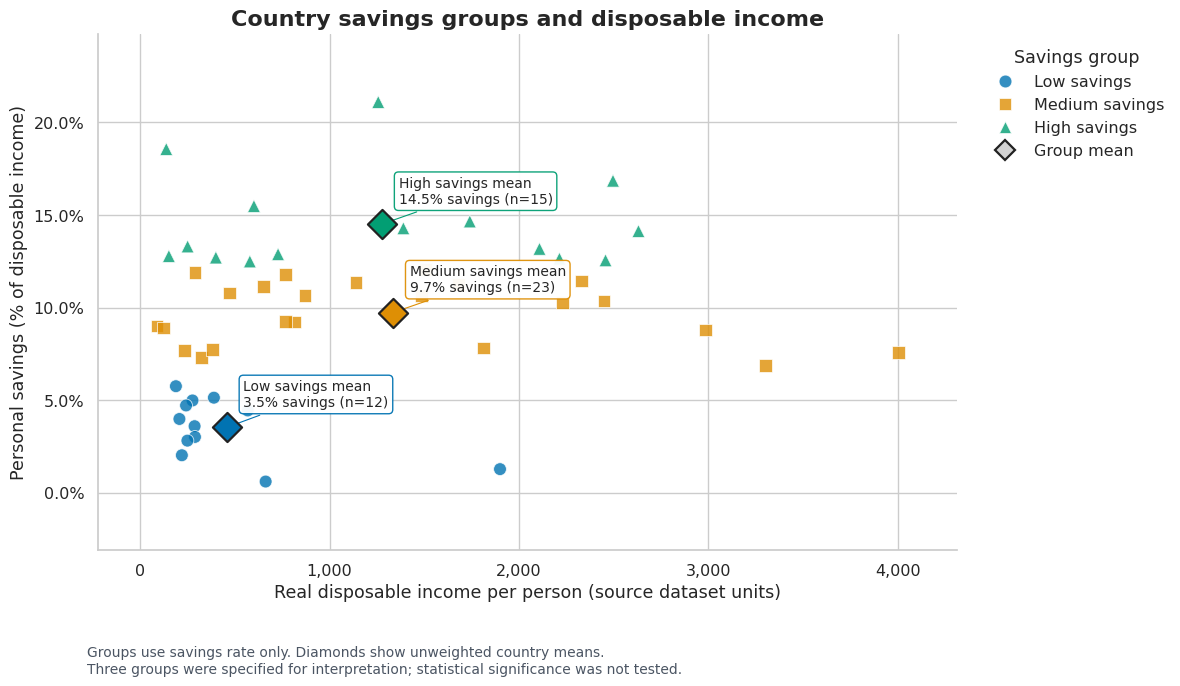

In [31]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

# Color and shape both identify groups, improving accessibility.
palette = dict(zip(group_order, sns.color_palette("colorblind", 3)))
country_markers = {"Low savings": "o", "Medium savings": "s", "High savings": "^"}

fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(
    data=df,
    x="dpi",
    y="sr",
    hue="Savings group",
    style="Savings group",
    hue_order=group_order,
    style_order=group_order,
    markers=country_markers,
    palette=palette,
    s=85,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.6,
    ax=ax
)

# Place each diamond at (mean income, mean savings rate) in ORIGINAL units.
# These are displayed group means; the model itself was fitted only on sr.
for group, row in group_summary.iterrows():
    ax.scatter(
        row["mean_dpi"], row["mean_sr"],
        marker="D", s=220, color=palette[group],
        edgecolor="#222222", linewidth=1.6, zorder=5
    )
    ax.annotate(
        f"{group} mean\n{row['mean_sr']:.1f}% savings (n={int(row['countries'])})",
        xy=(row["mean_dpi"], row["mean_sr"]),
        xytext=(12, 15),
        textcoords="offset points",
        fontsize=10,
        bbox={"boxstyle": "round,pad=0.3", "fc": "white",
              "ec": palette[group], "alpha": 0.95},
        arrowprops={"arrowstyle": "-", "color": palette[group], "lw": 0.8}
    )

ax.set(
    title="Country savings groups and disposable income",
    xlabel="Real disposable income per person (source dataset units)",
    ylabel="Personal savings (% of disposable income)"
)
ax.title.set_fontsize(16)
ax.title.set_fontweight("bold")
ax.title.set_position((0.5, 1.03))

# In the standard dataset, sr=10 means 10%, so do not multiply sr by 100.
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=1))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.margins(x=0.08, y=0.18)
sns.despine(ax=ax)

# Explain the diamond once in the legend.
handles, labels = ax.get_legend_handles_labels()
mean_handle = Line2D(
    [], [], marker="D", linestyle="",
    markerfacecolor="lightgray", markeredgecolor="#222222",
    markeredgewidth=1.6, markersize=10, label="Group mean"
)
ax.legend(
    handles=handles + [mean_handle],
    title="Savings group",
    bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False
)

fig.text(
    0.08, 0.025,
    "Groups use savings rate only. Diamonds show unweighted country means.\n"
    "Three groups were specified for interpretation; statistical significance was not tested.",
    fontsize=10, color="#4b5563"
)
fig.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()


In [32]:
# This table connects every plotted observation to a named country.
display(
    df[["Country", "Savings group", "sr", "dpi"]]
      .sort_values(["Savings group", "sr", "Country"])
      .rename(columns={
          "sr": "Savings (%)",
          "dpi": "Income (source units)"
      })
      .reset_index(drop=True)
)


,Country,Savings group,Savings (%),Income (source units)
0,Chile,Low savings,0.60,662.86
1,Iceland,Low savings,1.27,1900.10
2,Paraguay,Low savings,2.02,220.56
3,Tunisia,Low savings,2.81,249.87
4,Guatamala,Low savings,3.01,289.71
5,Ecuador,Low savings,3.59,287.77
6,Korea,Low savings,3.98,207.68
7,Panama,Low savings,4.44,568.56
8,Malaysia,Low savings,4.71,242.69
9,Colombia,Low savings,4.98,276.65


In [33]:
# Silhouette measures separation on sr, the variable used for clustering.
# It is a descriptive diagnostic, not a p-value or proof of natural groups.
# This comparison does not change the three-group model or its assignments.
diagnostics = []
largest_k = min(5, len(df) - 1, df["sr"].nunique())

for k in range(2, largest_k + 1):
    candidate = KMeans(n_clusters=k, random_state=42, n_init=20)
    candidate_labels = candidate.fit_predict(df[["sr"]])
    diagnostics.append({
        "Number of groups": k,
        "Silhouette score": silhouette_score(df[["sr"]], candidate_labels),
        "Smallest group (countries)": pd.Series(candidate_labels).value_counts().min()
    })

cluster_diagnostics = pd.DataFrame(diagnostics)
display(cluster_diagnostics.round(3))


,Number of groups,Silhouette score,Smallest group (countries)
0,2,0.589,18
1,3,0.509,12
2,4,0.575,4
3,5,0.562,3


In [34]:
display(
    df[df["Savings group"] == "High savings"]
    .groupby("Savings group", observed=True)[
        ["sr", "pop15", "pop75", "dpi", "ddpi"]
    ]
    .mean()
)

,sr,pop15,pop75,dpi,ddpi
Savings group,,,,,
High savings,14.504,31.175333,2.627333,1276.351333,4.523333


The overall means are nearly an identical match to the generated numbers provided by the LLM, with the exceptions being the value in 'pop15' and 'pop75' having been rounded in it's output. This finding is consistent with my previous assignments, where rounding is done to mathmatic standards but without any instruction from the user providing the prompt. The country cluster assignments appear to show the mean values of three sorted groups - low, medium, and high savings behavior groups. As the individual data points do noticably cluster among each group set, it is worth investigating how these clusters ended up occuring - are the graph's axis set and scaled appropriately, and has the grouping methodology been reviewed for real-life soundness? Given that we have not formally studied this method, or the code bringing it to life, we have a much more limited set of tools to interrogate and verify these outputs, which makes them much less reliable in our hands. Ideally, we would be using these exercises as a practice during the learning process, and not as a stopgap in a professional setting.